# E-Commerce Sales and Customer Behaviour Analytics Dashboard
**Capstone Project #2** · Tools: Python, Pandas, NumPy, Matplotlib, Plotly

**Business question:** Which categories, customers, regions and months drive revenue, and does price affect how much customers buy?

**Notebook outline:** 1) Dataset → 2) Data inspection → 3) Correlation → 4) groupby analysis → 5) Matplotlib charts → 6) Interactive Plotly dashboard → 7) HTML export → 8) Reflection

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from plotly.subplots import make_subplots

pd.set_option("display.float_format", "{:,.2f}".format)

## 1. Create the dataset
A synthetic dataset of **60 orders** (2025) is generated with a fixed random seed, so everyone gets the same data.
Prices are in ₹. Demand is built to fall as price rises, and sales are higher in the festive season (Oct–Dec), like real e-commerce data.

*To use your own data instead, skip this cell and run `df = pd.read_csv("your_file.csv", parse_dates=["Order_Date"])`.*

In [14]:
rng = np.random.default_rng(42)
n = 60

catalog = {
    "Electronics":    [("Wireless Earbuds", 2499), ("Smart Watch", 4999), ("Power Bank", 1299), ("Bluetooth Speaker", 1999)],
    "Fashion":        [("Running Shoes", 2199), ("Denim Jacket", 1799), ("Backpack", 1199), ("Sunglasses", 899)],
    "Home & Kitchen": [("Air Fryer", 3499), ("Mixer Grinder", 2799), ("Bedsheet Set", 999), ("Water Bottle", 449)],
    "Beauty":         [("Face Serum", 649), ("Perfume", 1199), ("Hair Dryer", 1499), ("Sunscreen", 349)],
    "Books":          [("Python Handbook", 499), ("Data Science Guide", 699), ("Novel Bestseller", 299), ("Study Planner", 199)],
}
cats = list(catalog)
cat_w = [0.28, 0.24, 0.20, 0.14, 0.14]
month_w = np.array([5, 4, 4, 5, 5, 5, 6, 6, 7, 9, 14, 12], float)
month_w /= month_w.sum()

rows = []
for i in range(n):
    cat = rng.choice(cats, p=cat_w)
    prod, base = catalog[cat][rng.integers(0, 4)]
    price = int(round(base * rng.uniform(0.95, 1.05), -1))
    lam = max(0.6, 6.0 - 1.1 * np.log(price / 150))      # pricier -> fewer units
    qty = int(max(1, rng.poisson(lam)))
    month = rng.choice(np.arange(1, 13), p=month_w)
    day = rng.integers(1, 29)
    disc = int(rng.choice([0, 5, 10, 15, 20], p=[.35, .2, .2, .15, .1]))
    rows.append(dict(
        Order_ID=f"ORD{1001 + i}",
        Order_Date=pd.Timestamp(2025, int(month), int(day)),
        Customer_ID=f"C{rng.integers(1, 31):03d}",
        Customer_Type=rng.choice(["New", "Returning"], p=[.4, .6]),
        Category=cat, Product=prod, Product_Price=price, Quantity=qty,
        Discount_Pct=disc, Sales=round(price * qty * (1 - disc / 100), 2),
        Region=rng.choice(["North", "South", "East", "West"], p=[.3, .25, .2, .25]),
        Payment_Method=rng.choice(["UPI", "Credit Card", "Debit Card", "COD"], p=[.4, .25, .2, .15]),
    ))

df = pd.DataFrame(rows).sort_values("Order_Date").reset_index(drop=True)
df["Month"] = df["Order_Date"].dt.to_period("M")
df.to_csv("ecommerce_sales.csv", index=False)
df.head()

,Order_ID,Order_Date,Customer_ID,Customer_Type,Category,Product,Product_Price,Quantity,Discount_Pct,Sales,Region,Payment_Method,Month
0,ORD1032,2025-01-01,C001,Returning,Books,Study Planner,190,5,0,950.00,West,UPI,2025-01
1,ORD1053,2025-01-04,C029,New,Fashion,Denim Jacket,1770,1,5,"1,681.50",South,COD,2025-01
2,ORD1007,2025-01-19,C024,Returning,Fashion,Denim Jacket,1810,4,0,"7,240.00",North,Credit Card,2025-01
3,ORD1013,2025-01-19,C017,Returning,Fashion,Running Shoes,2250,3,10,"6,075.00",West,UPI,2025-01
4,ORD1008,2025-02-10,C004,Returning,Electronics,Power Bank,1320,4,20,"4,224.00",East,UPI,2025-02


## 2. Data inspection
`shape`, `info()`, `describe()` and `value_counts()`

In [15]:
print("Shape (rows, columns):", df.shape)
print()
df.info()

Shape (rows, columns): (60, 13)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60 entries, 0 to 59
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Order_ID        60 non-null     object        
 1   Order_Date      60 non-null     datetime64[ns]
 2   Customer_ID     60 non-null     object        
 3   Customer_Type   60 non-null     object        
 4   Category        60 non-null     object        
 5   Product         60 non-null     object        
 6   Product_Price   60 non-null     int64         
 7   Quantity        60 non-null     int64         
 8   Discount_Pct    60 non-null     int64         
 9   Sales           60 non-null     float64       
 10  Region          60 non-null     object        
 11  Payment_Method  60 non-null     object        
 12  Month           60 non-null     period[M]     
dtypes: datetime64[ns](1), float64(1), int64(3), object(7), period[M](1)
memory usag

In [16]:
display(df.describe())

,Order_Date,Product_Price,Quantity,Discount_Pct,Sales
count,60,60.00,60.00,60.00,60.00
mean,2025-08-02 19:36:00,"1,754.67",3.35,6.42,"4,811.70"
min,2025-01-01 00:00:00,190.00,1.00,0.00,272.00
25%,2025-04-20 18:00:00,957.50,2.00,0.00,"2,363.00"
50%,2025-09-01 00:00:00,"1,480.00",3.00,5.00,"4,535.50"
75%,2025-11-09 06:00:00,"2,175.00",4.25,10.00,"6,235.50"
max,2025-12-28 00:00:00,"5,100.00",7.00,20.00,"14,940.00"
std,NaN,"1,234.15",1.58,6.52,"3,297.96"


In [17]:
for col in ["Category", "Customer_Type", "Region", "Payment_Method"]:
    print(f"--- {col} ---")
    print(df[col].value_counts())
    print()
print("Missing values:", df.isna().sum().sum())

--- Category ---
Category
Fashion           16
Beauty            14
Electronics       12
Home & Kitchen    10
Books              8
Name: count, dtype: int64

--- Customer_Type ---
Customer_Type
Returning    33
New          27
Name: count, dtype: int64

--- Region ---
Region
East     18
West     14
South    14
North    14
Name: count, dtype: int64

--- Payment_Method ---
Payment_Method
UPI            26
Credit Card    13
COD            11
Debit Card     10
Name: count, dtype: int64

Missing values: 0


**Inspection notes:** 60 orders, no missing values. Dates are real `datetime` values, so they can be grouped by month. Fashion and Electronics have the most orders; Books has the fewest.

## 3. Correlation
Does a higher price mean fewer units sold?

In [18]:
num_cols = ["Product_Price", "Quantity", "Discount_Pct", "Sales"]
corr = df[num_cols].corr()
display(corr)

price_qty_corr = df["Product_Price"].corr(df["Quantity"])
price_sales_corr = df["Product_Price"].corr(df["Sales"])
print(f"Price vs Quantity: r = {price_qty_corr:.2f}  (negative -> pricier items sell fewer units)")
print(f"Price vs Sales:    r = {price_sales_corr:.2f}  (positive -> pricier items still bring in more revenue per order)")

,Product_Price,Quantity,Discount_Pct,Sales
Product_Price,1.00,-0.40,-0.10,0.67
Quantity,-0.40,1.00,-0.17,0.24
Discount_Pct,-0.10,-0.17,1.00,-0.19
Sales,0.67,0.24,-0.19,1.00


Price vs Quantity: r = -0.40  (negative -> pricier items sell fewer units)
Price vs Sales:    r = 0.67  (positive -> pricier items still bring in more revenue per order)


**Interpretation:** Price and quantity have a moderate *negative* correlation, so customers buy fewer units of expensive products. But price and sales are *positively* correlated, so the lost volume does not cancel out the higher price: expensive items still earn more per order.

## 4. groupby() analysis

In [19]:
# 4a. Revenue by category
by_cat = (df.groupby("Category")
            .agg(Total_Sales=("Sales", "sum"), Orders=("Order_ID", "count"),
                 Avg_Order_Value=("Sales", "mean"), Units=("Quantity", "sum"))
            .sort_values("Total_Sales", ascending=False))
by_cat["Share_%"] = by_cat["Total_Sales"] / by_cat["Total_Sales"].sum() * 100
display(by_cat)

,Total_Sales,Orders,Avg_Order_Value,Units,Share_%
Category,,,,,
Fashion,"87,463.50",16,"5,466.47",59,30.30
Electronics,"71,218.50",12,"5,934.88",29,24.67
Beauty,"62,493.50",14,"4,463.82",60,21.65
Home & Kitchen,"57,586.00",10,"5,758.60",23,19.95
Books,"9,940.50",8,"1,242.56",30,3.44


In [20]:
# 4b. Revenue by month (months with no orders show as 0)
all_months = pd.period_range("2025-01", "2025-12", freq="M")
monthly = df.groupby("Month")["Sales"].sum().reindex(all_months, fill_value=0)
monthly.index = monthly.index.strftime("%b")
display(monthly.to_frame("Total_Sales"))

# 4c. Customer type and region
by_cust = df.groupby("Customer_Type")["Sales"].agg(["sum", "mean", "count"])
by_region = df.groupby("Region")["Sales"].sum().sort_values(ascending=False)
display(by_cust)
display(by_region.to_frame("Total_Sales"))

,Total_Sales
Jan,"15,946.50"
Feb,"19,349.50"
Mar,"18,322.50"
Apr,"30,555.00"
May,"10,371.00"
Jun,0.00
Jul,"24,344.00"
Aug,"23,929.50"
Sep,"12,785.00"
Oct,"52,057.50"


,sum,mean,count
Customer_Type,,,
New,"118,371.50","4,384.13",27
Returning,"170,330.50","5,161.53",33


,Total_Sales
Region,
East,"95,743.50"
South,"77,598.50"
West,"58,918.50"
North,"56,441.50"


In [21]:
# Key numbers used in the chart titles and the reflection
total_sales = df["Sales"].sum()
aov = df["Sales"].mean()
q4_share = df[df["Order_Date"].dt.month >= 10]["Sales"].sum() / total_sales * 100
peak_month = monthly.idxmax()
top_cat = by_cat.index[0]
top_cat_share = by_cat["Share_%"].iloc[0]
books_share = by_cat.loc["Books", "Share_%"]
ret_share = by_cust.loc["Returning", "sum"] / total_sales * 100
top_region = by_region.index[0]
top_region_share = by_region.iloc[0] / total_sales * 100

print(f"Total sales ₹{total_sales:,.0f} | Avg order ₹{aov:,.0f} | Q4 share {q4_share:.0f}% | Peak month {peak_month}")
print(f"Top category {top_cat} ({top_cat_share:.0f}%) | Books {books_share:.0f}% | Returning {ret_share:.0f}% | Top region {top_region} ({top_region_share:.0f}%)")

Total sales ₹288,702 | Avg order ₹4,812 | Q4 share 46% | Peak month Nov
Top category Fashion (30%) | Books 3% | Returning 59% | Top region East (33%)


## 5. Static visualizations (Matplotlib)
Three different chart types, each titled with its finding.

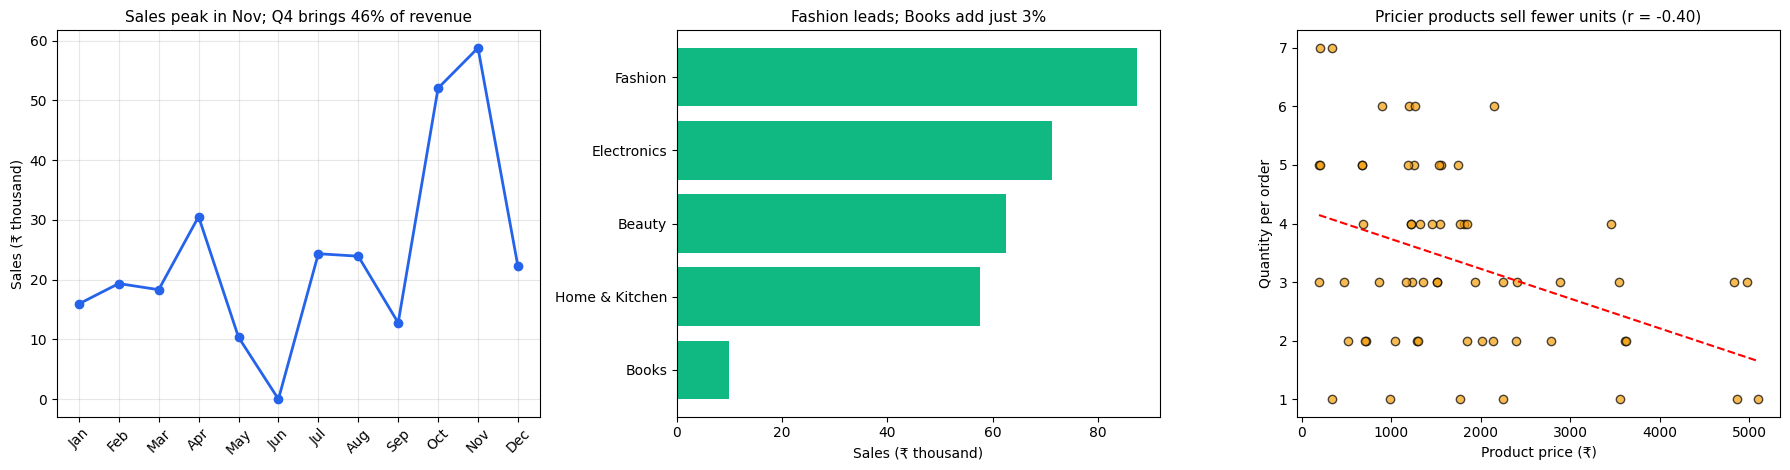

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))

# Line chart: monthly trend
axes[0].plot(monthly.index, monthly.values / 1000, marker="o", color="#2563eb", linewidth=2)
axes[0].set_title(f"Sales peak in {peak_month}; Q4 brings {q4_share:.0f}% of revenue", fontsize=11)
axes[0].set_ylabel("Sales (₹ thousand)"); axes[0].grid(alpha=.3)
axes[0].tick_params(axis="x", rotation=45)

# Bar chart: category revenue
axes[1].barh(by_cat.index[::-1], by_cat["Total_Sales"][::-1] / 1000, color="#10b981")
axes[1].set_title(f"{top_cat} leads; Books add just {books_share:.0f}%", fontsize=11)
axes[1].set_xlabel("Sales (₹ thousand)")

# Scatter + trend line: price vs quantity
axes[2].scatter(df["Product_Price"], df["Quantity"], alpha=.7, color="#f59e0b", edgecolor="k")
slope, intercept = np.polyfit(df["Product_Price"], df["Quantity"], 1)
xs = np.linspace(df["Product_Price"].min(), df["Product_Price"].max(), 50)
axes[2].plot(xs, slope * xs + intercept, "r--")
axes[2].set_title(f"Pricier products sell fewer units (r = {price_qty_corr:.2f})", fontsize=11)
axes[2].set_xlabel("Product price (₹)"); axes[2].set_ylabel("Quantity per order")

plt.tight_layout()
plt.show()

## 6. Interactive dashboard (Plotly)
Charts are ordered by importance: the **headline trend** comes first (full width), then **what sells** and **price effect**, then **who buys** and **where**.
Hover for details, click legend items to hide or show categories, and drag to zoom.

In [23]:
fig = make_subplots(
    rows=3, cols=2,
    specs=[[{"colspan": 2, "type": "xy"}, None],
           [{"type": "xy"}, {"type": "xy"}],
           [{"type": "domain"}, {"type": "xy"}]],
    subplot_titles=(
        f"1. Sales peak in {peak_month}: Q4 delivers {q4_share:.0f}% of annual revenue",
        f"2. {top_cat} leads revenue; Books add only {books_share:.0f}%",
        f"3. Higher price, fewer units (r = {price_qty_corr:.2f})",
        f"4. Returning customers drive {ret_share:.0f}% of sales",
        f"5. {top_region} is the strongest region ({top_region_share:.0f}%)",
    ),
    vertical_spacing=0.13, horizontal_spacing=0.10,
)

colors = {"Electronics": "#2563eb", "Fashion": "#f59e0b", "Home & Kitchen": "#10b981",
          "Beauty": "#ec4899", "Books": "#8b5cf6"}

# 1. Monthly sales trend (most important -> top, full width)
fig.add_trace(go.Scatter(x=monthly.index, y=monthly.values, mode="lines+markers", name="Monthly sales",
                         line=dict(color="#2563eb", width=3), fill="tozeroy", fillcolor="rgba(37,99,235,0.12)",
                         hovertemplate="%{x}: ₹%{y:,.0f}<extra></extra>", showlegend=False), row=1, col=1)

# 2. Category revenue
fig.add_trace(go.Bar(x=by_cat["Total_Sales"], y=by_cat.index, orientation="h",
                     marker_color=[colors[c] for c in by_cat.index],
                     hovertemplate="%{y}: ₹%{x:,.0f}<extra></extra>", showlegend=False), row=2, col=1)
fig.update_yaxes(autorange="reversed", row=2, col=1)

# 3. Price vs quantity (one trace per category so the legend can filter)
for cat in cats:
    d = df[df["Category"] == cat]
    fig.add_trace(go.Scatter(x=d["Product_Price"], y=d["Quantity"], mode="markers", name=cat,
                             marker=dict(color=colors[cat], size=10, line=dict(width=1, color="white")),
                             text=d["Product"], hovertemplate="%{text}<br>₹%{x:,} x %{y} units<extra>" + cat + "</extra>"),
                  row=2, col=2)
fig.add_trace(go.Scatter(x=xs, y=slope * xs + intercept, mode="lines", name="Trend",
                         line=dict(color="red", dash="dash"), hoverinfo="skip"), row=2, col=2)

# 4. Customer type donut
fig.add_trace(go.Pie(labels=by_cust.index, values=by_cust["sum"], hole=0.55,
                     marker=dict(colors=["#94a3b8", "#2563eb"]), textinfo="label+percent",
                     hovertemplate="%{label}: ₹%{value:,.0f}<extra></extra>", showlegend=False), row=3, col=1)

# 5. Regional sales
fig.add_trace(go.Bar(x=by_region.index, y=by_region.values, marker_color="#0ea5e9",
                     hovertemplate="%{x}: ₹%{y:,.0f}<extra></extra>", showlegend=False), row=3, col=2)

fig.update_xaxes(title_text="Product price (₹)", row=2, col=2)
fig.update_yaxes(title_text="Units per order", row=2, col=2)
fig.update_yaxes(title_text="Sales (₹)", row=1, col=1)
fig.update_layout(
    title=dict(text=f"E-Commerce Sales Dashboard 2025 · Total ₹{total_sales:,.0f} · {len(df)} orders · Avg order ₹{aov:,.0f}", x=0.5),
    height=1000, template="plotly_white", legend=dict(orientation="h", y=0.40, x=0.55),
    margin=dict(t=110, b=40),
)
fig.show()

## 7. Export the dashboard as HTML

In [24]:
fig.write_html("ecommerce_dashboard.html", include_plotlyjs="cdn")
print("Saved ecommerce_dashboard.html")

# In Google Colab, this downloads the files to your computer
try:
    from google.colab import files
    files.download("ecommerce_dashboard.html")
    files.download("ecommerce_sales.csv")
except ImportError:
    pass

Saved ecommerce_dashboard.html


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 8. Reflection
The dashboard shows that this store's revenue is driven by timing, product mix and loyal customers more than by volume alone. Sales are strongly seasonal: November is the peak month and the festive quarter (Oct–Dec) brings about 46% of annual revenue, so stock, ads and delivery capacity should be ready before October. Fashion and Electronics lead the categories, while Books contribute only about 3% of sales even though they sell as many units as Electronics, which suggests they work better as low-price add-ons than as a growth engine. Price and quantity are negatively correlated (r ≈ −0.40), so customers buy fewer units of expensive items, yet price and sales are positively correlated, so premium products still earn more per order. Returning customers generate about 59% of revenue and spend more per order than new ones, which makes retention offers a better investment than discounting, and East is the strongest region at roughly a third of total sales. The story: **sell premium products, prepare early for Q4, and keep existing customers coming back.** (The data is synthetic, so these patterns illustrate the method and should be re-checked on real data.)